# 📊 Exploration autonome

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 9h15** · 30 minutes, sans consignes techniques

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Faire un diagnostic rapide de votre jeu de données
- Identifier les variables clés pour le commanditaire
- Formuler trois premières hypothèses

## Le principe
Pendant 30 minutes, vous explorez **comme vous voulez**. Aucune consigne technique : seulement des questions auxquelles répondre à la fin.

1. Que représente une ligne ?
2. Quelle période, combien de clients, combien de lignes ?
3. Quelles variables comptent pour le commanditaire de votre brief ?
4. Quels problèmes de qualité voyez-vous ?
5. Quelles **trois hypothèses** voulez-vous tester aujourd'hui ?

In [ ]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r
From (redirected): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r&confirm=t&uuid=8c16668f-cd83-4674-b977-1daeb1fd81b9
To: /content/config_projet.py
100% 6.94k/6.94k [00:00<00:00, 24.0MB/s]
✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [ ]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "banque"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Crédit Azur · 20477 lignes, 20 colonnes


In [ ]:
from config_projet import brief
brief(SECTEUR)

# Brief · Crédit Azur

> Entreprise et données fictives, conçues pour la formation.

## Les commanditaires
**Marc Leroy, directeur des risques**, et **Inès Benali, responsable conformité.** Crédit Azur propose du crédit à la consommation en agence, en ligne et via des courtiers.

## Le contexte
- Le 1er mars 2024, un nouveau modèle de score (« score V2 ») a remplacé l'ancien pour décider de l'accord des crédits. Il pèse davantage l'ancienneté dans l'emploi et le type de contrat.
- Depuis, la production a baissé et des associations de consommateurs interpellent la banque sur l'accès au crédit des jeunes actifs.
- Le score d'octroi de crédit est un système d'IA à haut risque au sens du règlement européen sur l'IA : la conformité veut un état des lieux documenté.

## La demande
1. Comment évoluent les demandes, la production et le produit net bancaire (PNB) estimé ? Quelle saisonnalité, quel effet du score V2 ?
2. Quels types de crédit et quels canaux portent l'activité ?
3. Le score V2 a-t-il créé ou accentué des écarts entre groupes (âge, genre, région) ? Ces écarts s'expliquent-ils par des critères de risque ?
4. Que recommandez-vous, avec quels indicateurs de suivi, y compris d'inclusion financière ?

## Les données · `banque_credit_azur.csv`
Une ligne = une demande de crédit, de janvier 2023 à décembre 2025.

| Colonne | Description |
|---|---|
| `date_demande` | Date de la demande |
| `demande_id`, `client_id` | Identifiants |
| `genre`, `age`, `tranche_age`, `region` | Profil du demandeur |
| `canal` | `agence`, `web` ou `courtier` |
| `type_credit` | `auto`, `travaux`, `personnel`, `renouvelable` |
| `montant_demande`, `duree_mois` | Montant demandé (€) et durée |
| `revenu_mensuel` | Revenu net mensuel déclaré (€) |
| `taux_endettement` | Charges mensuelles, crédit compris, divisées par le revenu |
| `anciennete_emploi_ans`, `contrat` | Ancienneté dans l'emploi et type de contrat |
| `score_algo` | Score du modèle en vigueur à la date de la demande (0 à 1) |
| `credit_accorde` | 1 si le crédit a été accordé |
| `montant_accorde` | Montant accordé (0 si refus) |
| `pnb_estime_eur` | Produit net bancaire estimé sur la durée du crédit |
| `rembourse_sans_incident` | 1 si aucun incident sur 12 mois ; vide si le crédit a été refusé |

`reference_population.csv` donne la répartition de la population française adulte (approximation pédagogique inspirée de l'INSEE).


In [ ]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Votre exploration, autant de cellules que nécessaire


Ellipsis

In [13]:
df = pd.read_csv("/content/data/banque_credit_azur.csv")
df.head()

,date_demande,demande_id,client_id,genre,age,tranche_age,region,canal,type_credit,montant_demande,duree_mois,revenu_mensuel,taux_endettement,anciennete_emploi_ans,contrat,score_algo,credit_accorde,montant_accorde,pnb_estime_eur,rembourse_sans_incident
0,2023-01-01,DEM000000,CA00460,F,48,45-54,Ouest,web,personnel,8500.0,48,2650.0,0.312,24.9,CDI,0.954,1,8500.0,595.00,1.0
1,2023-01-01,DEM000001,CA02527,H,45,45-54,Nord-Est,courtier,personnel,5900.0,36,2190.0,0.168,3.1,CDI,0.869,1,5900.0,309.75,1.0
2,2023-01-02,DEM000022,CA13928,H,25,25-34,Sud-Est,agence,travaux,19300.0,72,1790.0,0.323,3.6,CDI,0.715,1,19300.0,2026.50,1.0
3,2023-01-02,DEM000021,CA01869,H,43,35-44,Ouest,agence,personnel,5600.0,24,2390.0,0.208,5.7,CDI,0.817,1,5600.0,196.00,1.0
4,2023-01-02,DEM000020,CA03301,H,43,35-44,Sud-Est,agence,travaux,12500.0,60,2780.0,0.167,13.6,CDI,0.922,1,12500.0,1093.75,1.0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20477 entries, 0 to 20476
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   date_demande             20477 non-null  object 
 1   demande_id               20477 non-null  object 
 2   client_id                20477 non-null  object 
 3   genre                    20477 non-null  object 
 4   age                      20477 non-null  int64  
 5   tranche_age              20477 non-null  object 
 6   region                   20477 non-null  object 
 7   canal                    20477 non-null  object 
 8   type_credit              20477 non-null  object 
 9   montant_demande          20477 non-null  float64
 10  duree_mois               20477 non-null  int64  
 11  revenu_mensuel           19895 non-null  float64
 12  taux_endettement         20477 non-null  float64
 13  anciennete_emploi_ans    20477 non-null  float64
 14  contrat               

Le dataset contient 20 477 lignes (demandes de crédit) et 20 colonnes

In [15]:
df.describe(include= 'all')

,date_demande,demande_id,client_id,genre,age,tranche_age,region,canal,type_credit,montant_demande,duree_mois,revenu_mensuel,taux_endettement,anciennete_emploi_ans,contrat,score_algo,credit_accorde,montant_accorde,pnb_estime_eur,rembourse_sans_incident
count,20477,20477,20477,20477,20477.000000,20477,20477,20477,20477,20477.000000,20477.000000,19895.000000,20477.000000,20477.000000,20477,20477.000000,20477.000000,20477.000000,20477.000000,13104.000000
unique,1094,20395,11173,2,NaN,6,6,3,4,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN
top,2025-05-05,DEM006142,CA06365,H,NaN,25-34,Nord-Est,agence,personnel,NaN,NaN,NaN,NaN,NaN,CDI,NaN,NaN,NaN,NaN,NaN
freq,46,2,8,11703,NaN,5322,4754,8697,6143,NaN,NaN,NaN,NaN,NaN,14593,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,42.320945,NaN,NaN,NaN,NaN,11130.990868,46.156371,2537.656698,0.352357,7.517761,NaN,0.686156,0.639937,6722.024711,522.638949,0.975122
std,NaN,NaN,NaN,NaN,14.751770,NaN,NaN,NaN,NaN,7454.138263,18.617209,984.872907,0.177884,6.690554,NaN,0.228422,0.480030,7449.156066,674.706016,0.155759
min,NaN,NaN,NaN,NaN,17.000000,NaN,NaN,NaN,NaN,500.000000,12.000000,530.000000,0.050000,0.000000,NaN,0.013000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,31.000000,NaN,NaN,NaN,NaN,5600.000000,36.000000,1820.000000,0.220000,2.700000,NaN,0.554000,0.000000,0.000000,0.000000,1.000000
50%,NaN,NaN,NaN,NaN,40.000000,NaN,NaN,NaN,NaN,9500.000000,48.000000,2370.000000,0.317000,5.600000,NaN,0.752000,1.000000,4900.000000,236.250000,1.000000
75%,NaN,NaN,NaN,NaN,52.000000,NaN,NaN,NaN,NaN,14800.000000,60.000000,3060.000000,0.447000,10.400000,NaN,0.865000,1.000000,11000.000000,883.750000,1.000000


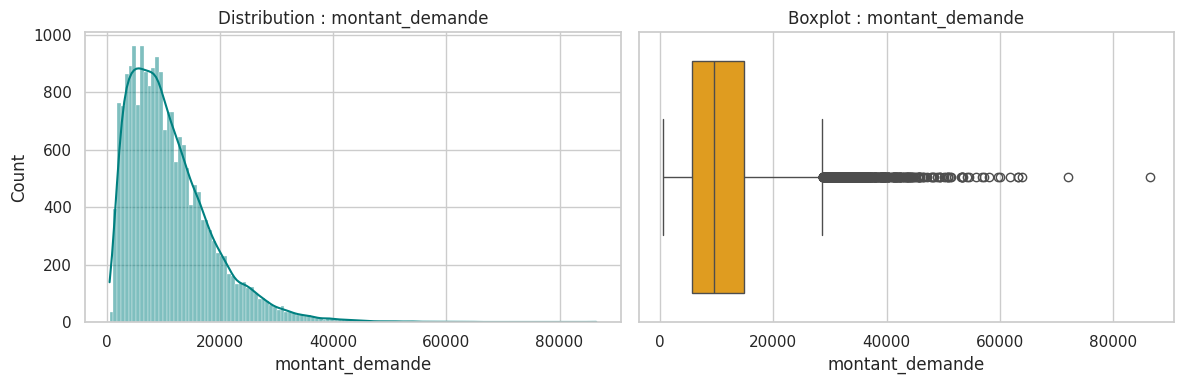

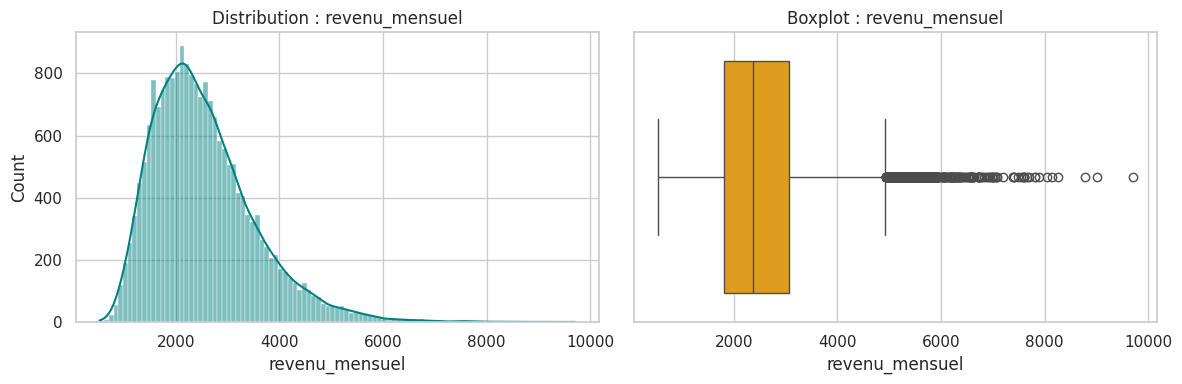

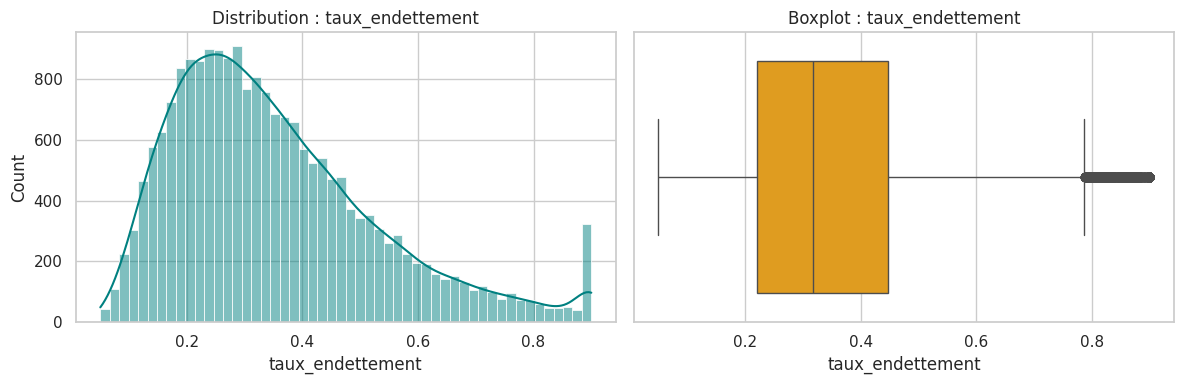

In [27]:
# 3. Visualisations univariées : Histogrammes et Boxplots
colonnes_a_observer = ['montant_demande', 'revenu_mensuel', 'taux_endettement']

for col in colonnes_a_observer:
    if col in df.columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        # Histogramme
        sns.histplot(df[col].dropna(), kde=True, ax=axes[0], color='teal')
        axes[0].set_title(f'Distribution : {col}')

        # Boxplot pour détecter les valeurs aberrantes (outliers)
        sns.boxplot(x=df[col].dropna(), ax=axes[1], color='orange')
        axes[1].set_title(f'Boxplot : {col}')

        plt.tight_layout()
        plt.show()

- montant_demande : la distribution est fortement asymétrique. La médiane se situe autour de 9 500 €, mais le boxplot met en évidence des valeurs extrêmes (outliers) allant jusqu'à 86 500 €, ce qui peut correspondre à des projets de plus grande envergure.
- revenu_mensuel : la médiane autour de 2 370 €, avec des revenus s'étalant de 530 € à plus de 9 700 €, reflétant une clientèle aux profils diversifiés
- taux endetement : la moyenne de 35%, avec des extrêmes atteignant 90%, ce qui est un indicateur de risque critique surveillé de près par la direction des risques.

In [28]:
# 📊 Code pour obtenir le tableau récapitulatif par mois
import pandas as pd

# 1. Conversion de la date et extraction du mois-année
df['date_demande'] = pd.to_datetime(df['date_demande'])
df['mois_annee'] = df['date_demande'].dt.to_period('M').astype(str)

# 2. Agrégation par mois (nombre de demandes, crédits accordés, production et PNB)
mensuel = df.groupby('mois_annee').agg(
    nb_demandes=('demande_id', 'count'),
    credits_accordes=('credit_accorde', 'sum'),
    production_totale=('montant_accorde', lambda x: f"{x.sum():.1f}"),
    pnb_total=('pnb_estime_eur', 'sum')
).reset_index()

# 3. Ajout de l'index pour correspondre au format attendu
mensuel['index'] = range(len(mensuel))
colonnes_ordre = ['index', 'mois_annee', 'nb_demandes', 'credits_accordes', 'production_totale', 'pnb_total']
mensuel = mensuel[colonnes_ordre]

# Affichage du résultat
display(mensuel.head(6))

# Si vous voulez l'exporter au format JSON exact :
# print(mensuel.head(6).to_json(orient='records'))

,index,mois_annee,nb_demandes,credits_accordes,production_totale,pnb_total
0,0,2023-01,455,357,3850700.0,299871.25
1,1,2023-02,526,404,4215400.0,325696.00
2,2,2023-03,693,523,5370000.0,415801.75
3,3,2023-04,592,452,4780600.0,367258.50
4,4,2023-05,677,518,5615600.0,445452.00
5,5,2023-06,625,473,5230600.0,412616.75


In [30]:
df.duplicated().sum()

np.int64(82)

In [31]:
df.isna().mean()

,0
date_demande,0.000000
demande_id,0.000000
client_id,0.000000
genre,0.000000
age,0.000000
tranche_age,0.000000
region,0.000000
canal,0.000000
type_credit,0.000000
montant_demande,0.000000


## Vos réponses
1. Une ligne = une demande de credit

2. Période et volumes Du 1er janvier 2023 au 31 décembre 2025. On a 20 477 lignes (demandes) et 20 colonnes.

3. Variables clés :
- Pour piloler le risque : montant_demande, revenu_mensuel, taux_endettement, score_algo, credit_accorde, pnb_estime_eur
- pour la conformité : tranche_age, genre, region, canal, type_credit, anciennete_emploi_ans, contrat

4. Problèmes de qualité :
- date_demande : Lue initialement comme du texte (object), nécessitant une conversion en format datetime pour l'analyse temporelle.
- revenu_mensuel : Contient des valeurs manquantes (19 895 valeurs non nulles sur 20 477)
- rembourse_sans_incident : Présente de nombreuses valeurs manquantes (uniquement 13 104 non nulles), ce qui est normal car la donnée est vide pour les crédits refusés.

5. Hypothèses :
- H1 : La refonte du site et le lancement de l'application en avril 2024 ont généré une augmentation significative du volume de commandes en ligne.   

- H2 : L'algorithme d'offres personnalisées cible principalement les clients fidèles déjà actifs, pénalisant les clients plus âgés ou moins connectés.  

- H3 : Les clients disposant de la carte de fidélité affichent un taux de rachat à 90 jours (rachat_90j) nettement supérieur aux clients non encartés.   

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Exploration : hypothèses H1 à H3 »